# KAIST: FM51 versus numerical LI-Init across 60-second rollouts

This notebook evaluates checkpoint **`runs/kaist_pooled_calibration_fm.8_topology_179/best.pt`** against a ROS-free, LI-Init-inspired numerical optimizer. It follows the FM rollout protocol from notebooks **51** and **45**, with the source measurements and numerical methods from **01_evaluate_li_init**.

**Target:** deliberately perturb **left LiDAR rotation only**, leaving the nominal IMU and right LiDAR unchanged. Both methods are scored on the true rotation `T_B_L` from the KAIST nominal rig. The FM receives all three sensors (`imu`, `lidar`, `lidar_right`); the numerical baseline uses IMU + left LiDAR odometry only. This is a sensor-input advantage for FM and must be stated when presenting results.

**Two separate comparisons, each with 60 physical seconds (12 × 5 s):**

1. **5-s joint:** run `solve_Rot_bias_gyro` on each new, individual 5-s sensor interval, warm-started from its previous rotation estimate. Old measurement residuals are **not** accumulated.
2. **Expanding 5→60-s joint:** re-optimize all measurements *seen so far* at each step, producing a genuine causal convergence trace whose final fit uses the complete 60-s interval. This is **not** a 60-s estimate available at 5 seconds.

Ten distinct, non-overlapping physical 60-s starts are selected across the requested KAIST recordings. Each subplot shows the **mean** SO(3) error across those starts for FM and one numerical variant. Percentile bands show the spread. Timing is measured with GPU synchronization where applicable and excludes dataset loading and file I/O.

**Benchmark caveats:** baseline IMU padding (configurable) is additional information needed to search unknown temporal offsets; the FM consumes the nominal unpadded 5-s network window. Only rotation is corrected for the FM, and only rotation is scored; the numerical optimizer estimates time and gyro bias as nuisance variables. The nominal rig matrices are used only for initializing artificial errors and scoring, never passed to the numerical optimizer as true extrinsics.

## 1. Imports, project root, and reproducibility

In [1]:
from pathlib import Path
from dataclasses import replace
from time import perf_counter
import gc
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciRotation
from scipy.integrate import trapezoid
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir() and (candidate / "src" / "baselines").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run this notebook in nn-obs-calib; src/obscalib and src/baselines are required.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from kaist_dataset.imu import load_imus
from kaist_dataset.lidar import load_lidar_relative_poses
from obscalib.config import (WindowingConfig, TransformerConfig, CalibrationPoolerConfig, MLPConfig,
                             PooledCalibrationHeadConfig, PooledCalibrationModelConfig, PooledCalibrationFlowConfig,
                             CalibrationFlowIntegratorConfig)
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint
from baselines.li_init import LIInitConfig, lidar_increments_to_motion
from baselines.li_init.adapters import (kaist_records_to_li_init, slice_li_init_window,
                                         reference_from_body_calibrations)
from baselines.li_init.rotation import solve_Rot_bias_gyro
from baselines.li_init.temporal import xcorr_temporal_init
from baselines.li_init.benchmark import rotation_error_degrees

print("Root:", ROOT, "| Torch:", torch.__version__)

Root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126


## 2. Experiment configuration

In [2]:
# Physical paths from KAIST notebooks 01 / 51. Set these to your own locations.
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.8_topology_179" / "best.pt"

# Use held-out KAIST recordings by default (FM51 trained on Urban08/12/13/14/15/16).
# Set ("Urban16",) only for reproducing the earlier in-distribution LI-Init experiments.
SEQUENCES = ("Urban38", "Urban39")
NUM_STARTS = 10
WINDOW_S = 5.0
ROLLOUT_S = 60.0
STEPS = int(ROLLOUT_S / WINDOW_S)
ANGLES_DEG = (0.0, 15.0, 30.0, 45.0, 60.0, 90.0, 120.0, 150.0, 179.0)
AXIS_SEEDS = 1                     # Additional axes require separate full sets of 10 physical starts.
RANDOM_SEED = 234567
TARGET_KEY = "lidar"
DATASET_MAX_SAMPLES_PER_SENSOR = 700

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
FM_ROTATION_GAIN = 1.0
FM_MAX_ROTATION_STEP_DEG = None

# Numerical estimator is warm-started from the same bad left-LiDAR rotation as FM.
# Keep time/bias estimates as nuisance variables; never supply GT to the solver.
NUMERIC_IMU_PADDING_S = 0.35
NUMERIC_TIME_BOUNDS = (-0.30, 0.30)
NUMERIC_MAX_COARSE_CANDIDATES = 2
NUMERIC_FILTERING = False
NUMERIC_MAX_NFEV = 200
NUMERIC_TEMPORAL_RESIDUAL = "interpolate"
NUMERIC_MAX_LIDAR_GAP_S = 0.75
NUMERIC_USE_PRIOR_ROTATION = True   # True: comparable initialization-angle sensitivity.

SHOW_PLOTS = True
OUTPUT_DIR = ROOT / "outputs" / "li_init_fm51_comparison"
PLOTS_DIR = ROOT / "outputs" / "plots" / "li_init_fm51_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

assert STEPS == 12 and WINDOW_S * STEPS == ROLLOUT_S
assert FM_INTEGRATION_METHOD in ("euler", "midpoint")
assert NUMERIC_IMU_PADDING_S >= max(abs(v) for v in NUMERIC_TIME_BOUNDS)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
print("Device:", DEVICE, "| checkpoint:", CHECKPOINT)
print("Dataset sequences:", SEQUENCES)
print("Numerical IMU padding:", NUMERIC_IMU_PADDING_S, "s per side")

Device: cuda | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt
Dataset sequences: ('Urban38', 'Urban39')
Numerical IMU padding: 0.35 s per side


## 3. Nominal KAIST rig and native three-sensor 5-second windows

In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)
T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.0],
    [0.0, 0.0, 1.0,  1.7],
    [0.0, 0.0, 0.0,  1.0],
], dtype=np.float64)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L,
                                       tau_imu_s=0.0, tau_lidar_s=0.0,
                                       T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
R_B_I = rig_calibration.T_B_I[:3, :3]
R_B_L_gt = rig_calibration.T_B_L[:3, :3]
R_I_L_gt = R_B_I.T @ R_B_L_gt
reference = reference_from_body_calibrations(rig_calibration.T_B_I, rig_calibration.T_B_L)
assert rotation_error_degrees(reference.R_LI, R_I_L_gt) < 0.01

for transform in (T_B_L, T_B_L_right, T_I_B):
    assert np.linalg.norm(transform[:3, :3].T @ transform[:3, :3] - np.eye(3)) < 5e-5

specs = build_kaist_sequence_specs(sequence_names=SEQUENCES, kaist_dataset_root=KAIST_DATASET_ROOT,
                                    lidar_pose_root=LIDAR_POSE_ROOT,
                                    lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"FM51 needs right LiDAR odometry: {spec.name} -> {spec.lidar_right_pose_csv}")
    if not spec.lidar_pose_csv.is_file():
        raise FileNotFoundError(spec.lidar_pose_csv)
    if not spec.sensor_data_root.is_dir():
        raise FileNotFoundError(spec.sensor_data_root)
if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)

windowing_config = WindowingConfig(window_duration_s=WINDOW_S, window_stride_s=WINDOW_S,
                                  max_samples_per_sensor=DATASET_MAX_SAMPLES_PER_SENSOR)
dataset = KAISTCalibrationDataset(specs, rig_calibration, windowing_config,
                                  measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64,
                                  window_timestamp_dtype=DTYPE)
assert tuple(dataset.calibration_keys) == ("imu", "lidar", "lidar_right"), dataset.calibration_keys
print("FM windows:", len(dataset))
for info in dataset.sequence_info:
    print(info.name, info.num_windows, "windows", "start", info.common_start_time_s)

FM windows: 699
Urban38 349 windows start 1559193240.21
Urban39 350 windows start 1559195806.12


## 4. Raw LiDAR/IMU series and **exact** retained-window start reconstruction

The FM's `KAISTCalibrationDataset` drops candidate windows without data. Consequently, dataset indices cannot safely be multiplied by five to reconstruct original timestamps. We recover each retained window's absolute start by matching its *first left LiDAR increment* against the original odometry grid and verify the resulting time and rotation. This also allows extra IMU padding in the numerical estimator while preserving exact 5-s windows for FM.

In [4]:
raw_by_sequence = {}
for spec in specs:
    recs = load_imus(spec.sensor_data_root, target_frequency_hz=None)
    if len(recs) == 1:
        imu_key = next(iter(recs))
    else:
        xsens = [key for key in recs if "xsens" in key.lower()]
        if len(xsens) != 1:
            raise ValueError(f"Select an unambiguous IMU stream for {spec.name}: {list(recs)}")
        imu_key = xsens[0]
    left = load_lidar_relative_poses(spec.lidar_pose_csv)
    imu, lidar = kaist_records_to_li_init(recs[imu_key], left, increment_convention="start_to_end")
    raw_by_sequence[spec.name] = dict(imu=imu, lidar=lidar, imu_key=imu_key)
    print(spec.name, "IMU:", imu_key, len(imu.t), "LiDAR edges:", len(lidar.t_start))


def np_array(tensor):
    return np.asarray(tensor.detach().cpu() if hasattr(tensor, "detach") else tensor, dtype=np.float64)


def recover_retained_starts(sequence, raw, common_start, count):
    """Recover true window start from a 5-s candidate grid, not stored array indices.

    Match the FIRST LiDAR measurement's endpoint and increment against the raw
    scan-pair record for each retained WindowSample, in chronological order.
    """
    sample_ids = [i for i in range(len(dataset)) if dataset.sequence_name_for_window(i) == sequence]
    assert len(sample_ids) == count, (sequence, len(sample_ids), count)
    source = raw["lidar"]
    start_times = []
    next_j = 0
    max_j = int(np.ceil((source.t_end[-1] - common_start) / WINDOW_S)) + 1
    for index in sample_ids:
        sample = dataset[index]
        left = sample.streams["lidar"]
        rel_end = float(np_array(left.timestamps)[0])
        rel_start = float(np_array(left.interval_start_timestamps)[0])
        edge = np_array(left.values)[0]
        matched = False
        for j in range(next_j, max_j):
            t0 = common_start + j * WINDOW_S
            absolute_end = t0 + rel_end
            pos = int(np.searchsorted(source.t_end, absolute_end))
            for k in (pos - 1, pos):
                if 0 <= k < len(source.t_end):
                    if abs(source.t_end[k] - absolute_end) < 0.004 and abs(source.t_start[k] - (t0 + rel_start)) < 0.004 and np.max(np.abs(source.delta_T[k] - edge)) < 2e-3:
                        start_times.append(t0)
                        next_j = j + 1
                        matched = True
                        break
            if matched:
                break
        if not matched:
            raise RuntimeError(f"Cannot reconcile {sequence} dataset window {index} with raw left-LiDAR timestamps. Check the dataset/odometry version and windowing contract.")
    return list(zip(sample_ids, start_times))

sample_info = {info.name: info for info in dataset.sequence_info}
window_start_by_id = {}
for name in SEQUENCES:
    matched = recover_retained_starts(name, raw_by_sequence[name],
                                      float(sample_info[name].common_start_time_s),
                                      int(sample_info[name].num_windows))
    window_start_by_id.update({i: t0 for i, t0 in matched})
    print(name, "recovered", len(matched), "exact physical start timestamps")
assert len(window_start_by_id) == len(dataset)

Urban38 IMU: sensor_data_xsens_imu 216225 LiDAR edges: 17005
Urban39 IMU: sensor_data_xsens_imu 186682 LiDAR edges: 17195
Urban38 recovered 349 exact physical start timestamps
Urban39 recovered 350 exact physical start timestamps


## 5. Pick ten **different, non-overlapping 60-second segments**

Candidates must have 12 consecutive 5-s neural windows, sufficient raw IMU coverage, and no large gaps in left-LiDAR odometry. We choose the ten physical starts evenly across all eligible nonoverlapping blocks. No random duplication is used to inflate the ensemble size.

In [5]:
def select_rollouts():
    eligible = []
    for name in SEQUENCES:
        pairs = [(i, window_start_by_id[i]) for i in range(len(dataset)) if dataset.sequence_name_for_window(i) == name]
        pairs.sort(key=lambda pair: pair[1])
        raw = raw_by_sequence[name]
        for j in range(0, len(pairs) - STEPS + 1):
            group = pairs[j:j + STEPS]
            ts = np.asarray([row[1] for row in group])
            if np.max(np.abs(np.diff(ts) - WINDOW_S)) > 0.005:
                continue
            t0 = float(ts[0])
            t1 = t0 + ROLLOUT_S
            if raw["imu"].t[0] > t0 - NUMERIC_IMU_PADDING_S or raw["imu"].t[-1] < t1 + NUMERIC_IMU_PADDING_S:
                continue
            lidar = raw["lidar"]
            a = np.searchsorted(lidar.t_end, t0, side="right")
            b = np.searchsorted(lidar.t_start, t1, side="left")
            if b - a < 2:
                continue
            gap = lidar.t_start[a+1:b] - lidar.t_end[a:b-1]
            if gap.size and gap.max() > NUMERIC_MAX_LIDAR_GAP_S:
                continue
            eligible.append(dict(sequence=name, start=t0, indices=[x[0] for x in group]))
    if not eligible:
        raise RuntimeError("No contiguous 60-s rollout candidates were found")
    # Greedy chronological nonoverlap selection within each recording.
    spaced = []
    last_ends = {}
    for entry in sorted(eligible, key=lambda r: (r["sequence"], r["start"])):
        if entry["start"] + 1e-6 < last_ends.get(entry["sequence"], -np.inf):
            continue
        spaced.append(entry)
        last_ends[entry["sequence"]] = entry["start"] + ROLLOUT_S
    if len(spaced) < NUM_STARTS:
        raise RuntimeError(f"Only {len(spaced)} independent 60-s blocks exist across {SEQUENCES}; requested {NUM_STARTS}. Reduce NUM_STARTS or include more recordings.")
    chosen = np.linspace(0, len(spaced) - 1, NUM_STARTS).round().astype(int)
    return [spaced[i] for i in np.unique(chosen)]

rollouts = select_rollouts()
assert len(rollouts) == NUM_STARTS
assert len({(r["sequence"], r["start"]) for r in rollouts}) == NUM_STARTS
print("Selected independent 60-s starts:")
display(pd.DataFrame([dict(sequence=r["sequence"], start_time_s=r["start"], start_dataset_index=r["indices"][0]) for r in rollouts]))

# Cache FM batches on the selected device; data loading is excluded from latency.
fm_windows = {}
for entry in rollouts:
    for index in entry["indices"]:
        if index not in fm_windows:
            fm_windows[index] = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
print("Cached", len(fm_windows), "unique FM 5-s inputs on", DEVICE)

Selected independent 60-s starts:


,sequence,start_time_s,start_dataset_index
0,Urban38,1.559193e+09,10
1,Urban38,1.559194e+09,82
2,Urban38,1.559194e+09,162
3,Urban38,1.559195e+09,224
4,Urban38,1.559195e+09,320
5,Urban39,1.559196e+09,399
6,Urban39,1.559196e+09,459
7,Urban39,1.559197e+09,540
8,Urban39,1.559197e+09,612
9,Urban39,1.559198e+09,685


Cached 120 unique FM 5-s inputs on cuda


## 6. Load FM51 and set up the exact tokenization/inference interface from notebook 45

In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12,
                                  dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
checkpoint_info = load_training_checkpoint(CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.eval().requires_grad_(False)
geometry_processor = GeometryProcessor()
print("FM checkpoint loaded; epoch", checkpoint_info.get("epoch"), "; parameters", sum(p.numel() for p in fm_model.parameters()))


def clone_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone()) for key, state in states.items()}


def clone_window_with_states(physical, states):
    """Do not change sensor observations or true calibration metadata; only the hypothesis."""
    return replace(physical, current_calibration=clone_states(states))


@torch.inference_mode()
def fm_forward(window, states):
    hypothesis = clone_window_with_states(window, states)
    keys = tuple(hypothesis.current_calibration)
    canonical = geometry_processor(hypothesis.streams, hypothesis.metadata, hypothesis.current_calibration)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError(f"Unexpected checkpoint token shape/routing: {tokens.x.shape}, {tokens.calibration_keys}")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    output = fm_model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    if set(output.predictions) != set(keys):
        raise RuntimeError(f"FM output keys: {list(output.predictions)} != {keys}")
    return output


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def rotation_error_B_L(R):
    return rotation_error_degrees(np.asarray(R), R_B_L_gt)


def trial_axis(start_id, axis_id):
    rng = np.random.default_rng(RANDOM_SEED + 1009 * start_id + 37 * axis_id)
    axis = rng.standard_normal(3)
    return axis / np.linalg.norm(axis)


def make_initial_states(physical, angle, axis):
    states = clone_states(physical.current_calibration)
    original = states[TARGET_KEY]
    T = original.transform.clone()
    delta = torch.as_tensor(np.deg2rad(angle) * axis, dtype=DTYPE, device=DEVICE).reshape(1, 3)
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    states[TARGET_KEY] = replace(original, transform=T)
    observed_error = rotation_error_B_L(T[0, :3, :3].detach().cpu().numpy())
    assert abs(observed_error - angle) < 0.06, (angle, observed_error)
    return states


@torch.inference_mode()
def apply_rotation_only_fm(states, output):
    """Update only the intended LiDAR rotation; other sensor states are frozen."""
    updated = clone_states(states)
    old = updated[TARGET_KEY]
    T = old.transform.clone()
    delta = output.predictions[TARGET_KEY].delta_xi[:, :3] * FM_ROTATION_GAIN
    if FM_MAX_ROTATION_STEP_DEG is not None:
        scale = (np.deg2rad(FM_MAX_ROTATION_STEP_DEG) / delta.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        delta = delta * scale
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    updated[TARGET_KEY] = replace(old, transform=T)
    for key in states:
        if key != TARGET_KEY:
            torch.testing.assert_close(states[key].transform, updated[key].transform, atol=0, rtol=0)
            torch.testing.assert_close(states[key].time_offset, updated[key].time_offset, atol=0, rtol=0)
    return updated

numeric_config = LIInitConfig(
    rotation_initialization="identity", filtering_enabled=NUMERIC_FILTERING,
    estimate_gyro_bias=True, estimate_time_offset=True,
    time_offset_bounds=NUMERIC_TIME_BOUNDS, xcorr_step=0.01,
    temporal_residual=NUMERIC_TEMPORAL_RESIDUAL, max_nfev=NUMERIC_MAX_NFEV,
    estimate_translation=False,
)
smoke = fm_windows[rollouts[0]["indices"][0]]
with torch.inference_mode():
    initial = make_initial_states(smoke, 90.0, np.array([1.0, 0.0, 0.0]))
    pred = fm_forward(smoke, initial)
    corrected = apply_rotation_only_fm(initial, pred)
    assert len(pred.predictions) == 3
    assert np.isfinite(rotation_error_B_L(corrected[TARGET_KEY].transform[0, :3, :3].cpu().numpy()))
print("FM51/KAIST 3-sensor checkpoint routing and 90° correction smoke: PASS")

FM checkpoint loaded; epoch 12 ; parameters 2555399


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


FM51/KAIST 3-sensor checkpoint routing and 90° correction smoke: PASS


## 7. Numerical joint optimizer and measured runtime

The numerical solver uses **the same warm-started initial angle** as FM, translated into the IMU's frame. Each update tries the strongest coarse time-correlation candidates and then jointly refines rotation, gyro bias, and temporal offset. On a solver error or failed observability check the last valid estimate is retained (and the failure is counted). Neither branch sees the reference calibration.

**Important:** The reference rotation is used only to create a known initial perturbation and to score estimates. The numerical solver never receives it as its target.

In [7]:
def fit_numeric(imu, lidar, R_prior, gyro_bias_prior, tau_prior):
    """LI-Init-style joint optimization from a supplied extrinsic rotation prior."""
    motion = lidar_increments_to_motion(lidar)
    temporal = xcorr_temporal_init(motion, imu, numeric_config)
    if temporal.success:
        candidate_offsets = np.asarray(temporal.candidate_offsets[:NUMERIC_MAX_COARSE_CANDIDATES], dtype=float)
    else:
        # Keep the failure visible; do not replace lack of excitation with a "success".
        return None, False, "coarse timing failed"
    if candidate_offsets.size == 0:
        return None, False, "no coarse temporal candidates"

    attempts = []
    for tau in candidate_offsets:
        lo, hi = numeric_config.time_offset_bounds
        if numeric_config.temporal_residual == "taylor":
            lo = max(lo, tau - numeric_config.temporal_local_half_width)
            hi = min(hi, tau + numeric_config.temporal_local_half_width)
        if hi <= lo:
            continue
        candidate_cfg = replace(numeric_config, initial_time_offset=float(tau), time_offset_bounds=(float(lo), float(hi)),
                                initial_gyro_bias=tuple(float(b) for b in gyro_bias_prior))
        try:
            result = solve_Rot_bias_gyro(motion, imu, candidate_cfg,
                                         initial_R_LI=np.asarray(R_prior) if NUMERIC_USE_PRIOR_ROTATION else None)
            attempts.append(result)
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError):
            continue
    if not attempts:
        return None, False, "no feasible joint solve"
    best = min(attempts, key=lambda r: (not r.success, r.rms_residual))
    return best, bool(best.success), str(best.message)


def numeric_step(raw, t0, t1, R_prior, bias_prior, tau_prior):
    """Time numerical calibration only, excluding disk I/O and array slicing."""
    imu, lidar = slice_li_init_window(raw["imu"], raw["lidar"], t0, t1,
                                       imu_padding_s=NUMERIC_IMU_PADDING_S)
    tic = perf_counter()
    try:
        result, success, message = fit_numeric(imu, lidar, R_prior, bias_prior, tau_prior)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
        result, success, message = None, False, f"{type(exc).__name__}: {exc}"
    elapsed_ms = 1000.0 * (perf_counter() - tic)
    if success:
        return result.R_LI.copy(), result.gyro_bias.copy(), float(result.time_offset), True, elapsed_ms, message
    return np.asarray(R_prior).copy(), np.asarray(bias_prior).copy(), float(tau_prior), False, elapsed_ms, message


def fm_step(window, states):
    sync_device()
    tic = perf_counter()
    with torch.inference_mode():
        output = fm_forward(window, states)
        updated = apply_rotation_only_fm(states, output)
    sync_device()
    return updated, 1000.0 * (perf_counter() - tic)

# Preflight: IMU-centered numerical initialization must represent exactly the
# same physical perturbed left-LiDAR rotation as the FM initial hypothesis.
first = rollouts[0]
sample_states = make_initial_states(fm_windows[first["indices"][0]], 60.0, trial_axis(0, 0))
R_B_L_prior = sample_states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
R_I_L_prior = R_B_I.T @ R_B_L_prior
assert rotation_error_degrees(R_B_I @ R_I_L_prior, R_B_L_prior) < 0.01
print("Numerical/NN reference-frame preflight: PASS")

Numerical/NN reference-frame preflight: PASS


## 8. Run *matched* physical rollouts from 10 different starts

Each row is scored against the actual nominal left-LiDAR rig rotation. The FM rollout is evaluated once per scenario and reused *only as stored results* in the two comparison modes. The numerical baseline is re-run from the same initial extrinsic in each mode. The baseline 5-s branch sees only the current 5-s data; the expanding branch refits the entire causal prefix, ending on a full 60-s fit.

The `elapsed_ms` column is actual computation time for that step; `total_compute_ms` is cumulative compute time, **not physical window time**. This notebook does not report unverified timing GT errors.

In [8]:
rows = []
MODE_5S = "5s_independent_joint"
MODE_60S = "cumulative_up_to_60s_joint"
METHOD_FM = "FM51"
METHOD_BASELINE = "LI-Init joint"


def add_row(mode, method, start_id, entry, angle, axis_id, step, R_B_L, last_ms, cum_ms, accepted, status):
    rows.append(dict(mode=mode, method=method, start_id=start_id, sequence=entry["sequence"],
                     physical_start_s=entry["start"], initial_deg=float(angle), axis_id=axis_id,
                     step=step, physical_elapsed_s=step * WINDOW_S,
                     rotation_error_deg=rotation_error_B_L(R_B_L),
                     elapsed_ms=float(last_ms), total_compute_ms=float(cum_ms),
                     accepted=accepted, status=str(status)))


for start_id, entry in enumerate(tqdm(rollouts, desc="Ten independent 60-s physical starts")):
    raw = raw_by_sequence[entry["sequence"]]
    base_physical = fm_windows[entry["indices"][0]]
    for axis_id in range(AXIS_SEEDS):
        axis = trial_axis(start_id, axis_id)
        for angle in ANGLES_DEG:
            initial_states = make_initial_states(base_physical, angle, axis)
            R_B_L0 = initial_states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
            R_I_L0 = R_B_I.T @ R_B_L0
            for mode in (MODE_5S, MODE_60S):
                add_row(mode, METHOD_FM, start_id, entry, angle, axis_id, 0, R_B_L0, 0, 0, np.nan, "initial")
                add_row(mode, METHOD_BASELINE, start_id, entry, angle, axis_id, 0, R_B_L0, 0, 0, np.nan, "initial")

            # Run FM only once, then log the same trajectory in both comparison tables.
            states = initial_states
            fm_total_ms = 0.0
            for step, index in enumerate(entry["indices"], 1):
                states, fm_ms = fm_step(fm_windows[index], states)
                fm_total_ms += fm_ms
                R_B_L = states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
                for mode in (MODE_5S, MODE_60S):
                    add_row(mode, METHOD_FM, start_id, entry, angle, axis_id, step,
                            R_B_L, fm_ms, fm_total_ms, True, "ok")

            # One fresh numeric prior per comparison mode, same physical initial error.
            for mode in (MODE_5S, MODE_60S):
                R_I_L = R_I_L0.copy()
                bias_g = np.asarray(numeric_config.initial_gyro_bias, dtype=float).copy()
                tau = float(numeric_config.initial_time_offset)
                numeric_total_ms = 0.0
                for step in range(1, STEPS + 1):
                    if mode == MODE_5S:
                        t0 = entry["start"] + (step - 1) * WINDOW_S
                    else:
                        t0 = entry["start"]
                    t1 = entry["start"] + step * WINDOW_S
                    try:
                        R_I_L, bias_g, tau, accepted, numeric_ms, status = numeric_step(raw, t0, t1, R_I_L, bias_g, tau)
                    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
                        accepted, numeric_ms, status = False, 0.0, f"{type(exc).__name__}: {exc}"
                    numeric_total_ms += numeric_ms
                    add_row(mode, METHOD_BASELINE, start_id, entry, angle, axis_id, step,
                            R_B_I @ R_I_L, numeric_ms, numeric_total_ms, accepted, status)
    print(f"Start {start_id+1}/{NUM_STARTS}: {entry['sequence']} {entry['start']:.3f}", flush=True)

rollout_df = pd.DataFrame(rows)
expected = NUM_STARTS * AXIS_SEEDS * len(ANGLES_DEG) * (STEPS + 1) * 2 * 2
assert len(rollout_df) == expected, (len(rollout_df), expected)
assert set(rollout_df["start_id"]) == set(range(NUM_STARTS))
assert rollout_df["rotation_error_deg"].notna().all()

# FM trajectories MUST be identical in both modes, and everyone starts at the requested error.
pivot_fm = rollout_df[rollout_df.method == METHOD_FM].pivot(index=["start_id", "axis_id", "initial_deg", "step"],
                                                             columns="mode", values="rotation_error_deg")
np.testing.assert_allclose(pivot_fm[MODE_5S], pivot_fm[MODE_60S], atol=0, rtol=0)
for angle, part in rollout_df[rollout_df.step == 0].groupby("initial_deg"):
    assert np.max(np.abs(part.rotation_error_deg - angle)) < 0.07

raw_csv = OUTPUT_DIR / "fm_vs_li_init_60s_rollouts_raw.csv"
rollout_df.to_csv(raw_csv, index=False)
print("Recorded", len(rollout_df), "rows to", raw_csv)
display(rollout_df.head())

Ten independent 60-s physical starts:   0%|          | 0/10 [00:00<?, ?it/s]

Start 1/10: Urban38 1559193300.210
Start 2/10: Urban38 1559193770.210
Start 3/10: Urban38 1559194185.210
Start 4/10: Urban38 1559194615.210
Start 5/10: Urban38 1559195240.210
Start 6/10: Urban39 1559196066.120


KeyboardInterrupt: 

## 9. Aggregate **mean across ten physical starts** and percentile ranges

In [ ]:
def q10(x):
    return float(x.quantile(0.1))


def q90(x):
    return float(x.quantile(0.9))

summary = (rollout_df.groupby(["mode", "method", "initial_deg", "step", "physical_elapsed_s"], as_index=False)
           .agg(n=("rotation_error_deg", "size"),
                mean_deg=("rotation_error_deg", "mean"), median_deg=("rotation_error_deg", "median"),
                q10_deg=("rotation_error_deg", q10), q90_deg=("rotation_error_deg", q90),
                mean_step_ms=("elapsed_ms", "mean"), median_step_ms=("elapsed_ms", "median"),
                mean_cumulative_ms=("total_compute_ms", "mean"),
                accepted_fraction=("accepted", "mean")))
assert (summary.n == NUM_STARTS * AXIS_SEEDS).all()
summary_csv = OUTPUT_DIR / "fm_vs_li_init_60s_rollouts_summary.csv"
summary.to_csv(summary_csv, index=False)
print("Mean aggregation: n =", NUM_STARTS * AXIS_SEEDS, "per subplot point. Saved", summary_csv)
display(summary[summary.step == STEPS].round(3))

Mean aggregation: n = 10 per subplot point. Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init_fm51_comparison/fm_vs_li_init_60s_rollouts_summary.csv


,mode,method,initial_deg,step,physical_elapsed_s,n,mean_deg,median_deg,q10_deg,q90_deg,mean_step_ms,median_step_ms,mean_cumulative_ms,accepted_fraction
12,5s_independent_joint,FM51,0.0,12,60.0,10,3.537,2.375,0.907,7.491,280.254,254.464,3464.626,1.0
25,5s_independent_joint,FM51,15.0,12,60.0,10,4.547,3.144,1.691,7.910,271.291,239.922,3282.339,1.0
38,5s_independent_joint,FM51,30.0,12,60.0,10,4.825,4.177,1.824,7.745,258.062,255.995,3245.576,1.0
51,5s_independent_joint,FM51,45.0,12,60.0,10,4.764,4.489,1.246,8.856,264.760,248.098,3187.847,1.0
64,5s_independent_joint,FM51,60.0,12,60.0,10,5.401,5.062,1.375,11.583,252.879,244.060,3148.668,1.0
77,5s_independent_joint,FM51,90.0,12,60.0,10,31.282,9.570,3.284,119.840,240.636,206.668,3227.482,1.0
90,5s_independent_joint,FM51,120.0,12,60.0,10,123.669,172.133,6.741,175.859,243.762,239.573,3182.892,1.0
103,5s_independent_joint,FM51,150.0,12,60.0,10,159.415,174.739,152.603,178.426,239.331,215.250,3210.489,1.0
116,5s_independent_joint,FM51,179.0,12,60.0,10,173.353,176.279,166.482,179.372,289.420,276.815,3174.417,1.0
129,5s_independent_joint,LI-Init joint,0.0,12,60.0,10,71.014,78.049,5.265,152.927,350.271,144.801,3225.354,0.9


## 10. Convergence plots: **two lines per subplot**, one subplot per starting angle

Two full figure sets are produced: a 5-s warm-started joint baseline, and a causal expanding-history baseline whose final step optimizes all 60 seconds. Each line is the **mean** over ten different physical starting segments, with 10th–90th percentile bands. An optional zoomed set makes near-5° behavior easier to inspect.

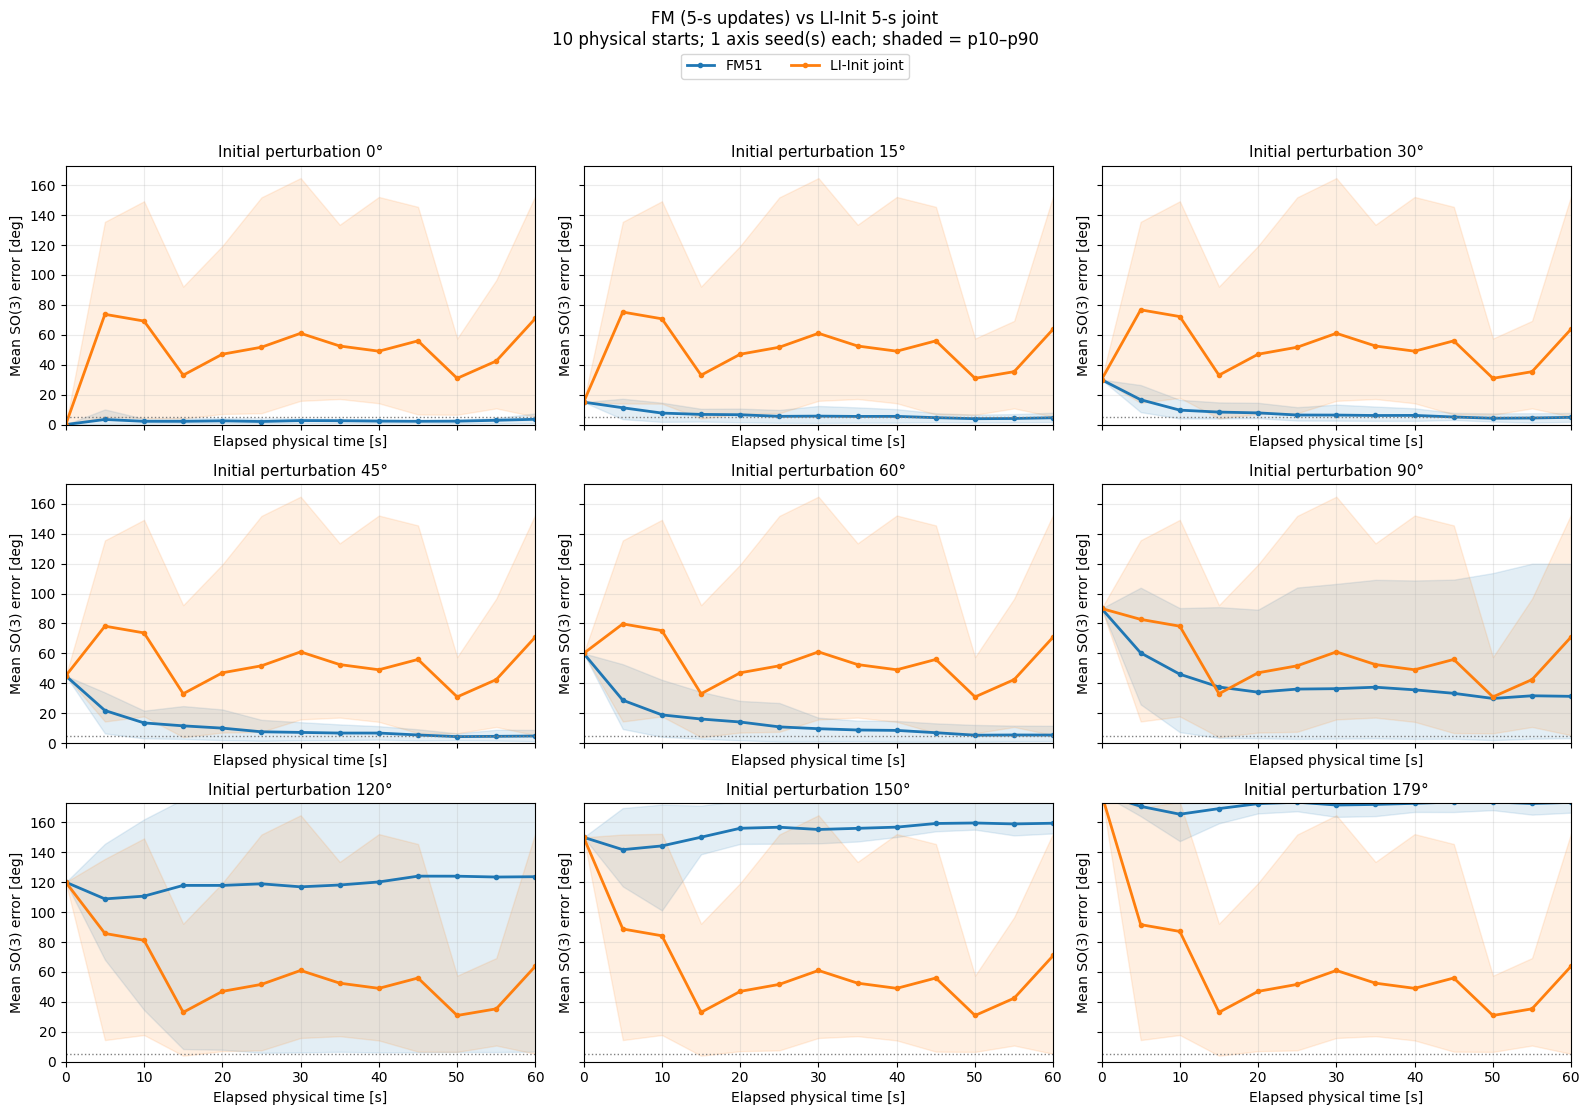

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/5s_independent_joint_rotation_full.png


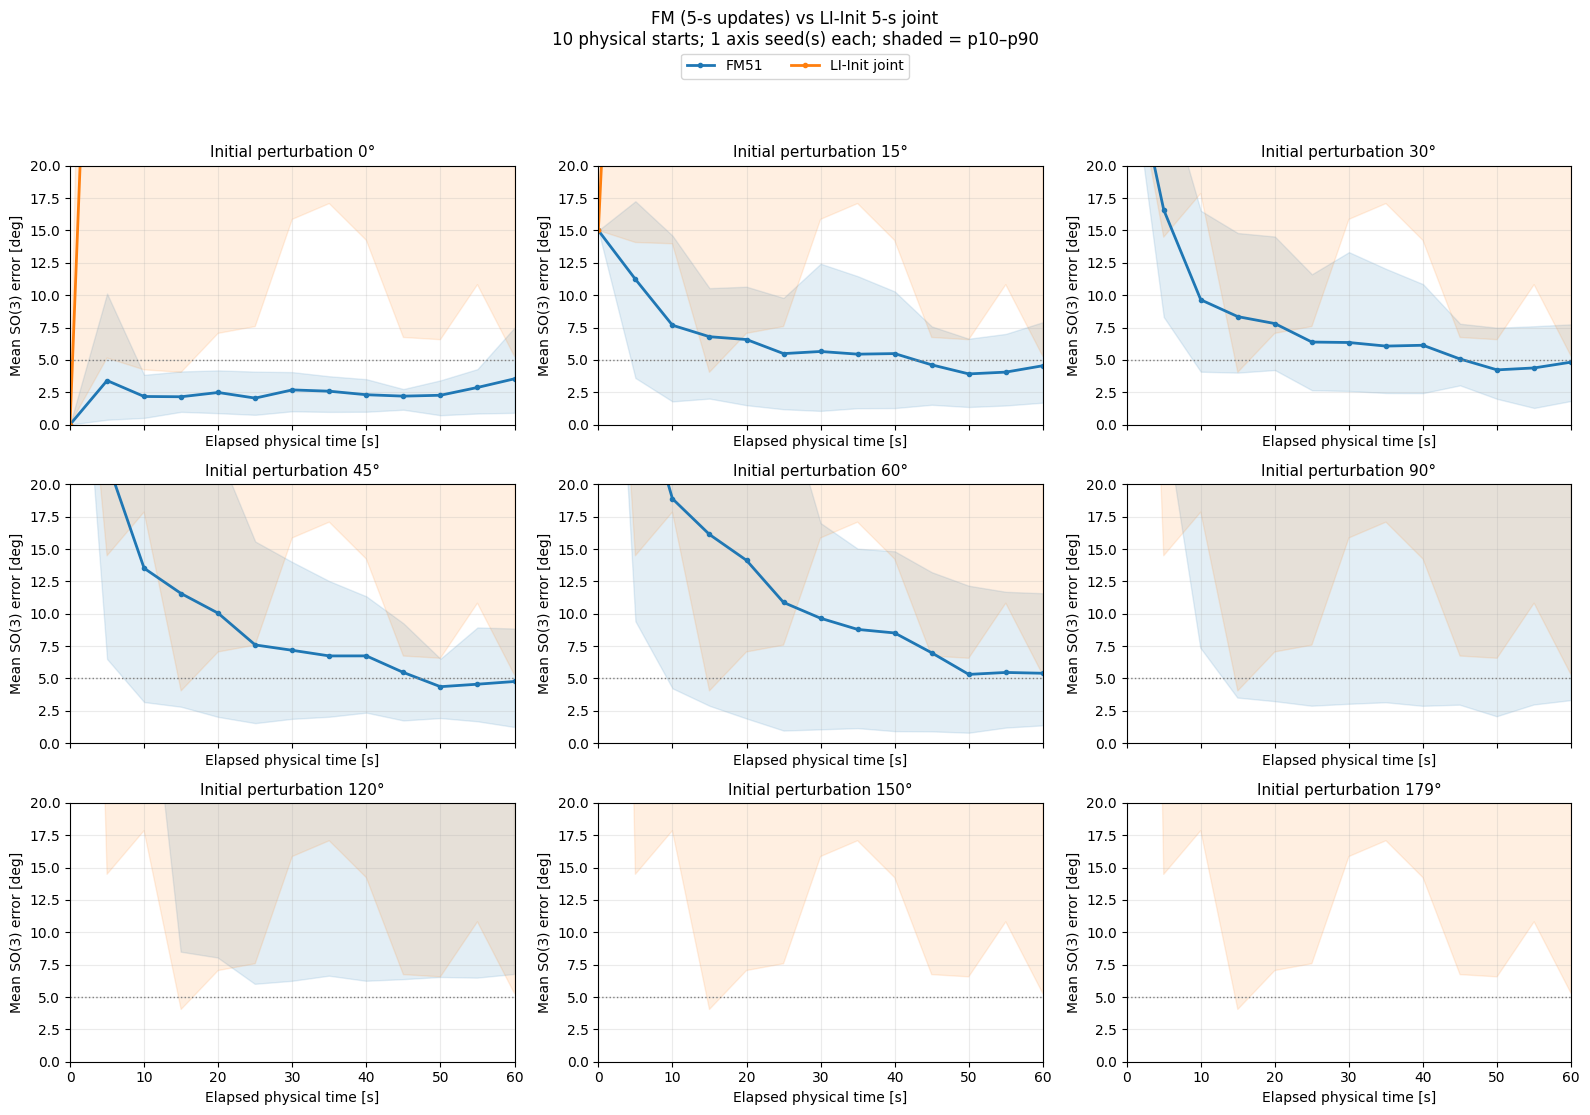

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/5s_independent_joint_rotation_zoom20deg.png


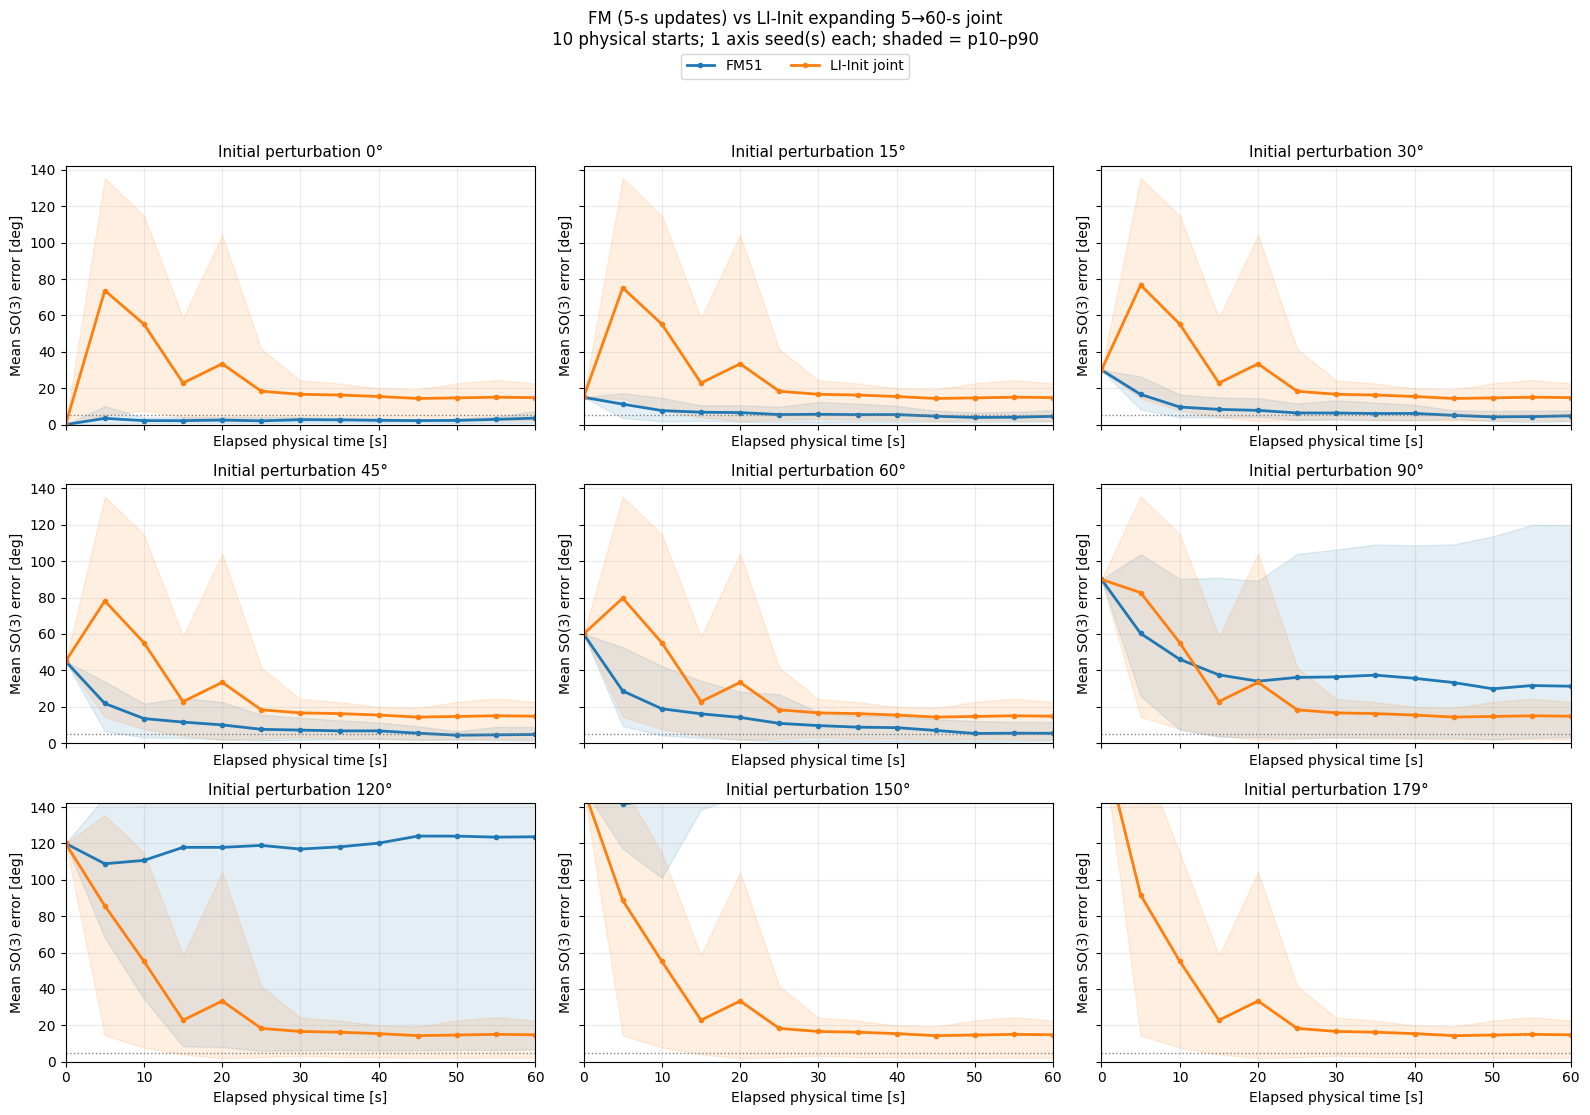

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/cumulative_up_to_60s_joint_rotation_full.png


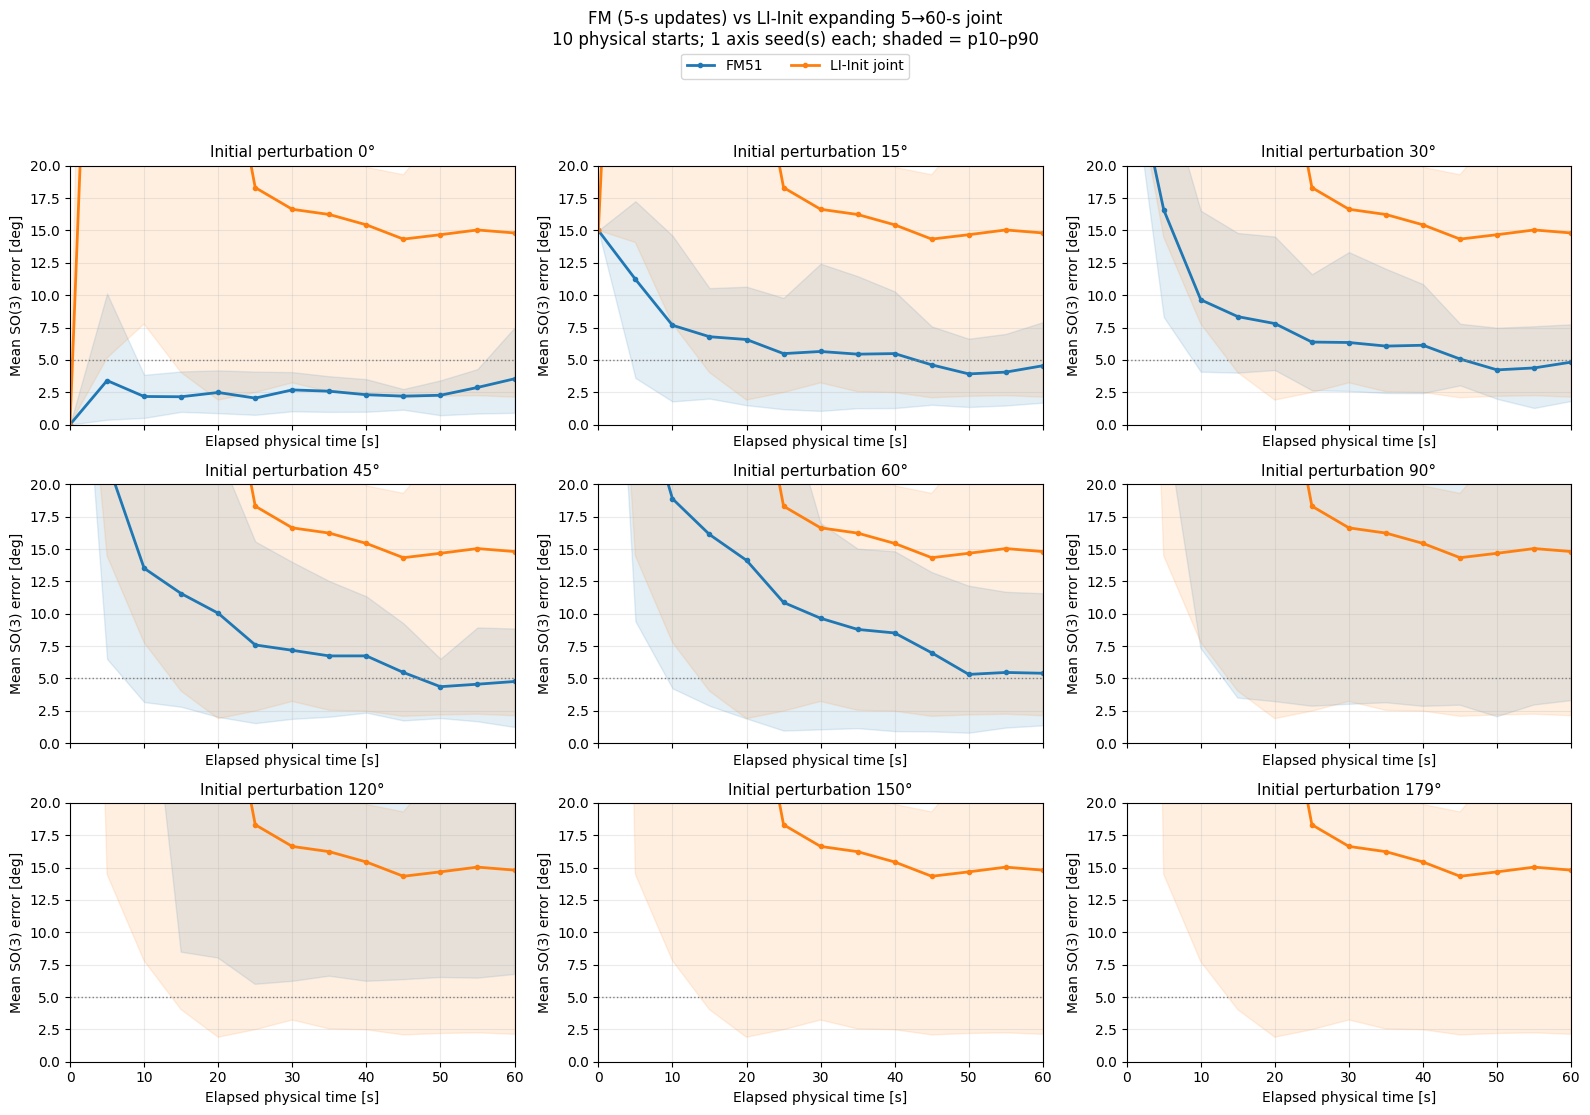

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/cumulative_up_to_60s_joint_rotation_zoom20deg.png


In [ ]:
COLORS = {METHOD_FM: "tab:blue", METHOD_BASELINE: "tab:orange"}
MODE_TITLES = {MODE_5S: "FM (5-s updates) vs LI-Init 5-s joint",
               MODE_60S: "FM (5-s updates) vs LI-Init expanding 5→60-s joint"}


def plot_angle_grid(mode, *, zoom_max=None):
    angles = list(ANGLES_DEG)
    ncols = 3
    nrows = int(np.ceil(len(angles) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.7 * nrows), sharex=True,
                             sharey=zoom_max is None, squeeze=False)
    for ax, angle in zip(axes.flat, angles):
        for method in (METHOD_FM, METHOD_BASELINE):
            part = summary[(summary["mode"] == mode) & (summary["initial_deg"] == angle) & (summary["method"] == method)].sort_values("step")
            x = part.physical_elapsed_s.to_numpy(dtype=float)
            ax.plot(x, part.mean_deg.to_numpy(), color=COLORS[method], marker="o", markersize=3,
                    linewidth=2.0, label=method)
            ax.fill_between(x, part.q10_deg.to_numpy(), part.q90_deg.to_numpy(), color=COLORS[method], alpha=0.12)
        ax.axhline(5.0, linestyle=":", linewidth=1, color="gray")
        ax.set_title(f"Initial perturbation {angle:g}°", fontsize=11)
        ax.set_xlim(0, ROLLOUT_S)
        ax.set_xticks(np.arange(0, ROLLOUT_S + 1, 10))
        if zoom_max is not None:
            ax.set_ylim(0, zoom_max)
        else:
            ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        ax.set_xlabel("Elapsed physical time [s]")
        ax.set_ylabel("Mean SO(3) error [deg]")
    for ax in axes.flat[len(angles):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.967), ncol=2)
    fig.suptitle(MODE_TITLES[mode] + f"\n{NUM_STARTS} physical starts; {AXIS_SEEDS} axis seed(s) each; shaded = p10–p90", y=1.00)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    suffix = "full" if zoom_max is None else f"zoom{zoom_max:g}deg"
    path = PLOTS_DIR / f"{mode}_rotation_{suffix}.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print("Saved:", path)


for mode in (MODE_5S, MODE_60S):
    plot_angle_grid(mode)
    plot_angle_grid(mode, zoom_max=20.0)

## 11. Runtime plots by starting angle

Cumulative computation time includes every numerical re-fit or FM inference up to each 5-s interval. For the expanding 60-s numerical variant, this grows because *all previous measurements are optimized again*. The right diagnostic compares **per-update time**, not cumulative time. These are wall-clock latencies, not physical travel time.

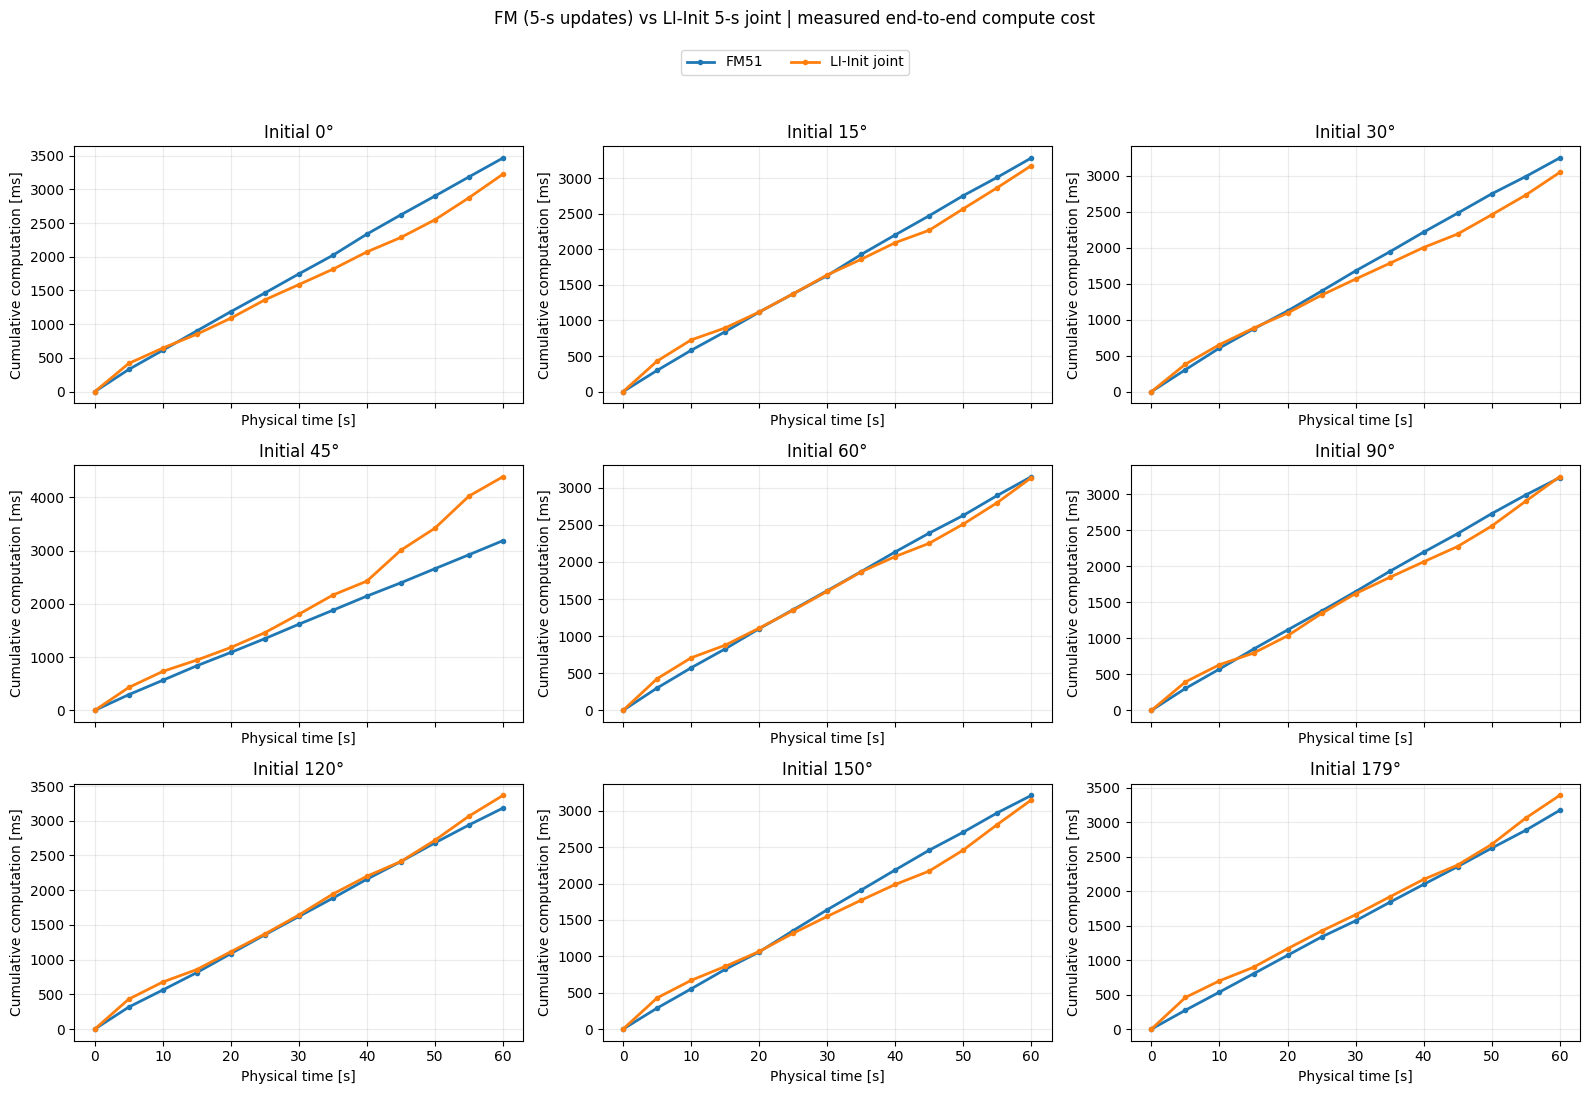

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/5s_independent_joint_cumulative_runtime.png


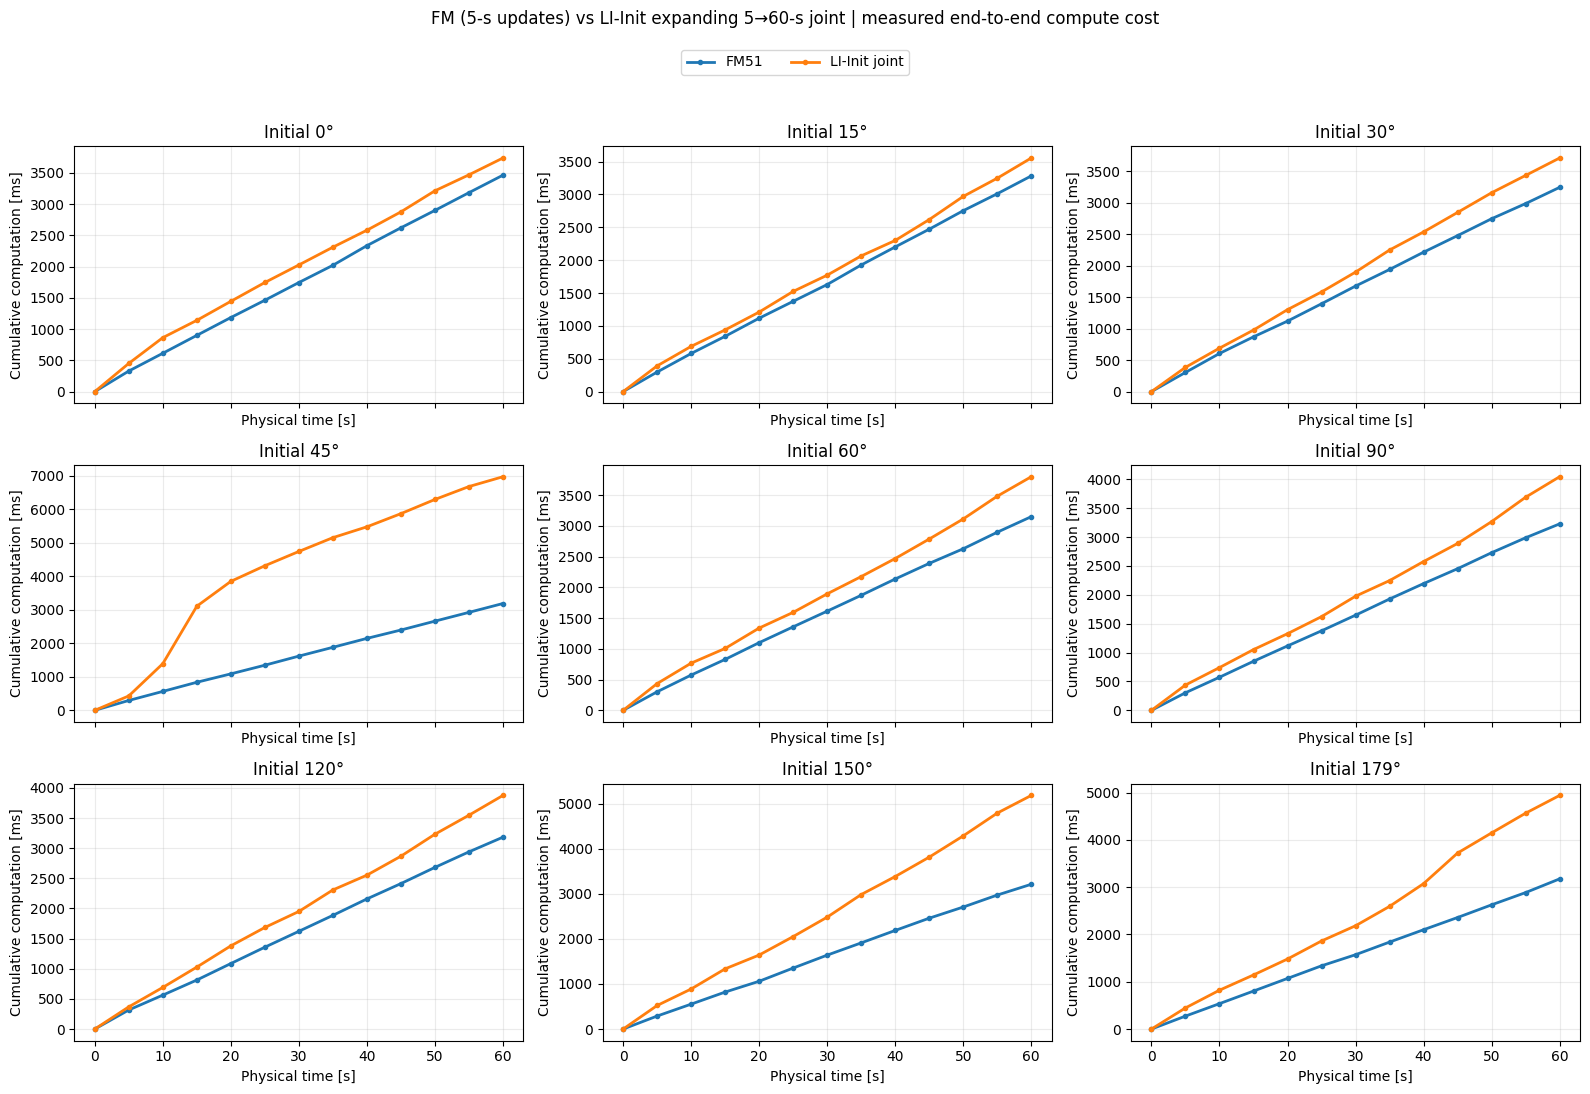

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init_fm51_comparison/cumulative_up_to_60s_joint_cumulative_runtime.png


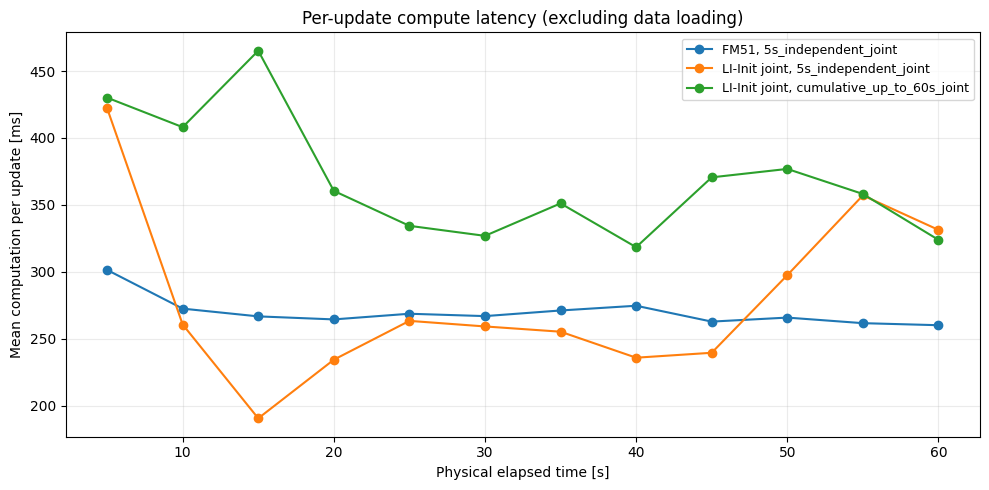

In [ ]:
def plot_runtime_grid(mode):
    angles = list(ANGLES_DEG)
    fig, axes = plt.subplots(int(np.ceil(len(angles) / 3)), 3, figsize=(16, 11), sharex=True, squeeze=False)
    for ax, angle in zip(axes.flat, angles):
        for method in (METHOD_FM, METHOD_BASELINE):
            part = summary[(summary["mode"] == mode) & (summary.initial_deg == angle) & (summary.method == method)].sort_values("step")
            ax.plot(part.physical_elapsed_s, part.mean_cumulative_ms, color=COLORS[method], linewidth=2, marker="o",
                    markersize=3, label=method)
        ax.set(title=f"Initial {angle:g}°", xlabel="Physical time [s]", ylabel="Cumulative computation [ms]")
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(angles):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2)
    fig.suptitle(MODE_TITLES[mode] + " | measured end-to-end compute cost", y=0.99)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    path = PLOTS_DIR / f"{mode}_cumulative_runtime.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print("Saved:", path)


for mode in (MODE_5S, MODE_60S):
    plot_runtime_grid(mode)

# Additionally compare per-update cost across the two numerical modes.
step_cost = (summary[summary.step > 0].groupby(["mode", "method", "step"], as_index=False)
             .agg(mean_ms=("mean_step_ms", "mean"), median_ms=("median_step_ms", "median")))
fig, ax = plt.subplots(figsize=(10, 5))
for (mode, method), part in step_cost.groupby(["mode", "method"]):
    if method == METHOD_FM and mode != MODE_5S:
        continue  # identical FM evaluations in each comparison
    ax.plot(part.step * WINDOW_S, part.mean_ms, marker="o", label=f"{method}, {mode}")
ax.set(xlabel="Physical elapsed time [s]", ylabel="Mean computation per update [ms]",
       title="Per-update compute latency (excluding data loading)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "per_update_runtime_comparison.png", dpi=175)
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

## 12. Endpoint and convergence-rate statistics

In [ ]:
endpoints = rollout_df[rollout_df.step == STEPS].copy()
endpoints["under_5deg"] = endpoints.rotation_error_deg < 5
endpoint_summary = (endpoints.groupby(["mode", "method", "initial_deg"], as_index=False)
                    .agg(n=("rotation_error_deg", "size"), mean_final_deg=("rotation_error_deg", "mean"),
                         median_final_deg=("rotation_error_deg", "median"),
                         p90_final_deg=("rotation_error_deg", q90),
                         success_under_5deg=("under_5deg", "mean"),
                         mean_compute_ms=("total_compute_ms", "mean")))

# Per-run area under error curve and first 5-degree recovery time.
trajectory_summary_rows = []
for (mode, method, start_id, axis_id, angle), group in rollout_df.groupby(
    ["mode", "method", "start_id", "axis_id", "initial_deg"], sort=False):
    group = group.sort_values("step")
    err = group.rotation_error_deg.to_numpy()
    elapsed = group.physical_elapsed_s.to_numpy()
    converged = np.flatnonzero((err < 5.0) & (elapsed > 0))
    trajectory_summary_rows.append(dict(mode=mode, method=method, start_id=start_id,
                                        axis_id=axis_id, initial_deg=angle,
                                        mean_error_over_time_deg=float(trapezoid(err, elapsed) / ROLLOUT_S),
                                        first_under_5deg_s=float(elapsed[converged[0]]) if len(converged) else np.nan,
                                        final_deg=float(err[-1]),
                                        final_under_5deg=bool(err[-1] < 5),
                                        compute_ms=float(group.total_compute_ms.iloc[-1])))
trajectory_summary = pd.DataFrame(trajectory_summary_rows)
summary_trajectories = (trajectory_summary.groupby(["mode", "method", "initial_deg"], as_index=False)
                        .agg(n=("start_id", "size"), time_mean_error_deg=("mean_error_over_time_deg", "mean"),
                             final_under_5deg=("final_under_5deg", "mean"),
                             first_under_5deg_median_s=("first_under_5deg_s", "median"),
                             compute_median_ms=("compute_ms", "median")))
display(endpoint_summary.round(3))
display(summary_trajectories.round(3))
endpoint_summary.to_csv(OUTPUT_DIR / "fm_vs_li_init_endpoints.csv", index=False)
trajectory_summary.to_csv(OUTPUT_DIR / "fm_vs_li_init_trajectory_runs.csv", index=False)
summary_trajectories.to_csv(OUTPUT_DIR / "fm_vs_li_init_convergence_statistics.csv", index=False)

# See how often the numerical optimization accepted a solution, independently of true error.
accepted = (rollout_df[(rollout_df.method == METHOD_BASELINE) & (rollout_df.step > 0)]
            .groupby(["mode", "initial_deg"], as_index=False)
            .agg(accepted_fraction=("accepted", "mean")))
display(accepted.round(3))

,mode,method,initial_deg,n,mean_final_deg,median_final_deg,p90_final_deg,success_under_5deg,mean_compute_ms
0,5s_independent_joint,FM51,0.0,10,3.537,2.375,7.491,0.7,3464.626
1,5s_independent_joint,FM51,15.0,10,4.547,3.144,7.910,0.6,3282.339
2,5s_independent_joint,FM51,30.0,10,4.825,4.177,7.745,0.6,3245.576
3,5s_independent_joint,FM51,45.0,10,4.764,4.489,8.856,0.6,3187.847
4,5s_independent_joint,FM51,60.0,10,5.401,5.062,11.583,0.5,3148.668
5,5s_independent_joint,FM51,90.0,10,31.282,9.570,119.840,0.2,3227.482
6,5s_independent_joint,FM51,120.0,10,123.669,172.133,175.859,0.0,3182.892
7,5s_independent_joint,FM51,150.0,10,159.415,174.739,178.426,0.0,3210.489
8,5s_independent_joint,FM51,179.0,10,173.353,176.279,179.372,0.0,3174.417
9,5s_independent_joint,LI-Init joint,0.0,10,71.014,78.049,152.927,0.1,3225.354


,mode,method,initial_deg,n,time_mean_error_deg,final_under_5deg,first_under_5deg_median_s,compute_median_ms
0,5s_independent_joint,FM51,0.0,10,2.408,0.7,5.0,3012.239
1,5s_independent_joint,FM51,15.0,10,6.390,0.6,10.0,2967.167
2,5s_independent_joint,FM51,30.0,10,8.197,0.6,15.0,3080.901
3,5s_independent_joint,FM51,45.0,10,10.369,0.6,17.5,2908.041
4,5s_independent_joint,FM51,60.0,10,13.843,0.5,12.5,2968.055
5,5s_independent_joint,FM51,90.0,10,39.918,0.2,15.0,2921.522
6,5s_independent_joint,FM51,120.0,10,118.553,0.0,25.0,2884.110
7,5s_independent_joint,FM51,150.0,10,154.116,0.0,NaN,2955.204
8,5s_independent_joint,FM51,179.0,10,171.954,0.0,NaN,2932.737
9,5s_independent_joint,LI-Init joint,0.0,10,50.168,0.1,12.5,2691.649


,mode,initial_deg,accepted_fraction
0,5s_independent_joint,0.0,0.958333
1,5s_independent_joint,15.0,0.95
2,5s_independent_joint,30.0,0.95
3,5s_independent_joint,45.0,0.958333
4,5s_independent_joint,60.0,0.958333
5,5s_independent_joint,90.0,0.958333
6,5s_independent_joint,120.0,0.95
7,5s_independent_joint,150.0,0.958333
8,5s_independent_joint,179.0,0.95
9,cumulative_up_to_60s_joint,0.0,0.916667


## 13. Interpretation and limitations

- **Physical timeline:** all models receive only information observed up to the current step. The *expanding* baseline uses 60 s only at the final point, avoiding 60-s lookahead at earlier points.
- **Input asymmetry:** FM has three physical sensor modalities (one IMU, two LiDARs), while the numerical optimizer uses one IMU and **left** LiDAR only. The FM checkpoint was trained for changing topologies but is evaluated on the original topology here.
- **Starting-angle fairness:** FM and the warm-started numerical optimizer begin at identical physical extrinsic rotations for every start and axis. The numerical solver's time/bias nuisance variables are initialized without GT.
- **Rotation-only protocol:** FM applies only the left-LiDAR SO(3) correction; no extrinsic translation or temporal update and no healthy-sensor drift. Numeric translation is disabled, but timing and bias are fitted as nuisance variables.
- **Duration:** mean FM model compute time aggregates 12 successive 5-s forward passes; the 5-s optimizer solves 12 separate 5-s problems; the expanding optimizer solves 5, 10, …, 60 seconds anew. Total runtime may therefore increase strongly for the expanding method. Data loading and model checkpoint initialization are excluded.
- **Ground truth:** the fixed KAIST matrices are **nominal rig extrinsics**. The zero timestamp offsets are *not* treated as verified temporal truth, so all accuracy plots concern rotation only. If the nominal extrinsics are approximate, that affects absolute accuracy claims.
- **Statistical validity:** ten *different* nonoverlapping 60-s starts, with independently seeded axes. Bands represent between-start variability, not confidence intervals. If 10 cannot be found, this notebook fails rather than silently repeating physical windows.
- **Failed solves:** failures retain the previous estimate; accepted-fit fractions are reported separately. A failed optimization must not be mistaken for a successful correction.
- **In-distribution vs held-out:** default `Urban38/Urban39` comes from FM51 test sequences. Replacing with `Urban16` reproduces the original numerical test but is not an out-of-training-set performance estimate.

**Next experiment:** add a stronger numerical cumulative *factor-graph/preintegration* baseline if the input-matched angular-velocity model is too noisy on short windows, or evaluate a two-LiDAR numerical rig estimator to remove the FM sensor-information advantage.

FM correction directions:   0%|          | 0/10 [00:00<?, ?it/s]

,initial_deg,step,elapsed_s,mean_cosine,median_cosine,wrong_direction_fraction,mean_predicted_deg,mean_ideal_deg,mean_improvement_deg,improvement_fraction
0,15.0,1,5.0,0.670,0.746,0.1,12.324,15.0,3.772,0.8
1,30.0,1,5.0,0.827,0.900,0.0,22.374,30.0,13.409,1.0
2,60.0,1,5.0,0.775,0.930,0.1,44.423,60.0,31.311,0.9
3,90.0,1,5.0,0.496,0.814,0.2,56.980,90.0,29.690,0.8
4,120.0,1,5.0,0.171,0.278,0.4,69.717,120.0,11.172,0.6
5,150.0,1,5.0,0.082,0.270,0.4,69.098,150.0,8.246,0.6
6,179.0,1,5.0,-0.046,0.003,0.5,71.527,179.0,8.318,1.0


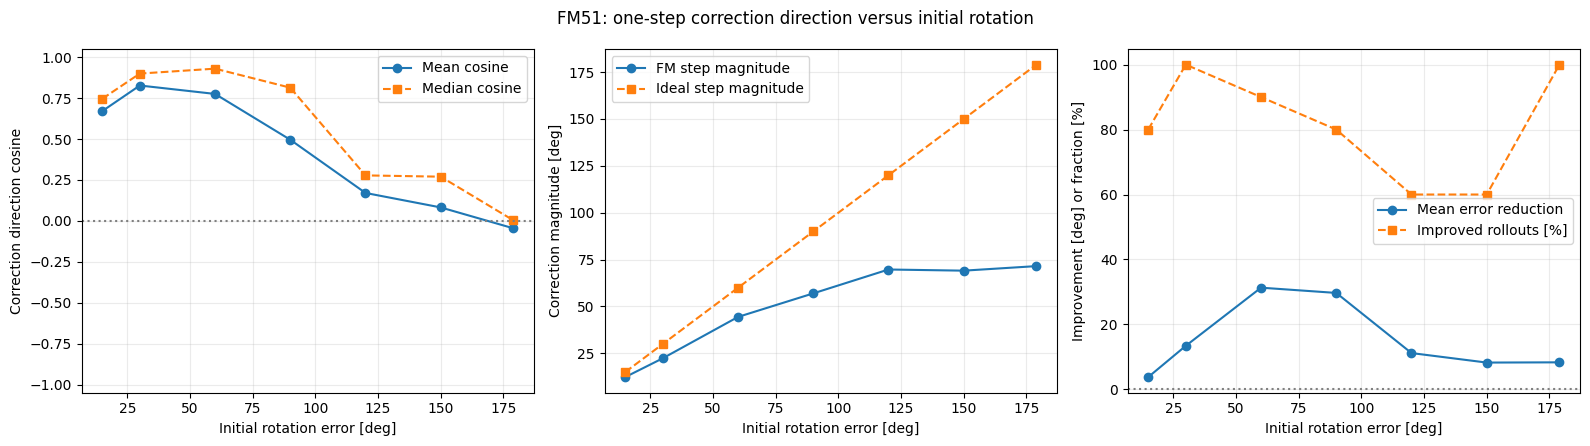

In [9]:

# Appendix A: FM correction direction versus true SO(3) correction.
# Requires notebook 02 cells through model initialization and rollout selection.

DIRECTION_ANGLES_DEG = (15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 179.0)
DIRECTION_FULL_ROLLOUT = False


def direction_cosine(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine between two left-multiplicative body-frame rotation vectors."""
    norm = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / norm) if norm > 1e-9 else np.nan


rows_direction = []

for start_id, entry in enumerate(tqdm(rollouts, desc="FM correction directions")):
    for axis_id in range(AXIS_SEEDS):
        axis = trial_axis(start_id, axis_id)

        for angle in DIRECTION_ANGLES_DEG:
            states = make_initial_states(fm_windows[entry["indices"][0]], angle, axis)
            indices = entry["indices"] if DIRECTION_FULL_ROLLOUT else entry["indices"][:1]

            for step, window_index in enumerate(indices, 1):
                R_prior = np_array(states[TARGET_KEY].transform[0, :3, :3])

                # The true correction is left-multiplied in body coordinates.
                ideal = SciRotation.from_matrix(R_B_L_gt @ R_prior.T).as_rotvec()

                with torch.inference_mode():
                    prediction = fm_forward(fm_windows[window_index], states)
                    proposed = np_array(prediction.predictions[TARGET_KEY].delta_xi[0, :3]) * FM_ROTATION_GAIN

                    if FM_MAX_ROTATION_STEP_DEG is not None:
                        limit = np.deg2rad(FM_MAX_ROTATION_STEP_DEG)
                        proposed *= min(1.0, limit / max(np.linalg.norm(proposed), 1e-12))

                    next_states = apply_rotation_only_fm(states, prediction)

                R_after = np_array(next_states[TARGET_KEY].transform[0, :3, :3])
                before = rotation_error_degrees(R_prior, R_B_L_gt)
                after = rotation_error_degrees(R_after, R_B_L_gt)

                rows_direction.append(dict(
                    start_id=start_id,
                    sequence=entry["sequence"],
                    axis_id=axis_id,
                    initial_deg=angle,
                    step=step,
                    elapsed_s=step * WINDOW_S,
                    correction_cosine=direction_cosine(proposed, ideal),
                    predicted_step_deg=np.rad2deg(np.linalg.norm(proposed)),
                    ideal_step_deg=np.rad2deg(np.linalg.norm(ideal)),
                    error_before_deg=before,
                    error_after_deg=after,
                    improvement_deg=before - after,
                ))

                states = next_states

direction_df = pd.DataFrame(rows_direction)

direction_summary = direction_df.groupby(
    ["initial_deg", "step", "elapsed_s"], as_index=False
).agg(
    mean_cosine=("correction_cosine", "mean"),
    median_cosine=("correction_cosine", "median"),
    wrong_direction_fraction=("correction_cosine", lambda x: float((x < 0).mean())),
    mean_predicted_deg=("predicted_step_deg", "mean"),
    mean_ideal_deg=("ideal_step_deg", "mean"),
    mean_improvement_deg=("improvement_deg", "mean"),
    improvement_fraction=("improvement_deg", lambda x: float((x > 0).mean())),
)

display(direction_summary.round(3))

direction_df.to_csv(OUTPUT_DIR / "fm_correction_direction_runs.csv", index=False)
direction_summary.to_csv(OUTPUT_DIR / "fm_correction_direction_summary.csv", index=False)

# First-step diagnostics.
first = direction_summary[direction_summary.step == 1].sort_values("initial_deg")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(first.initial_deg, first.mean_cosine, "o-", label="Mean cosine")
axes[0].plot(first.initial_deg, first.median_cosine, "s--", label="Median cosine")
axes[0].axhline(0, color="gray", ls=":")
axes[0].set(
    xlabel="Initial rotation error [deg]",
    ylabel="Correction direction cosine",
    ylim=(-1.05, 1.05),
)
axes[0].legend()

axes[1].plot(first.initial_deg, first.mean_predicted_deg, "o-", label="FM step magnitude")
axes[1].plot(first.initial_deg, first.mean_ideal_deg, "s--", label="Ideal step magnitude")
axes[1].set(
    xlabel="Initial rotation error [deg]",
    ylabel="Correction magnitude [deg]",
)
axes[1].legend()

axes[2].plot(first.initial_deg, first.mean_improvement_deg, "o-", label="Mean error reduction")
axes[2].plot(first.initial_deg, first.improvement_fraction * 100, "s--", label="Improved rollouts [%]")
axes[2].axhline(0, color="gray", ls=":")
axes[2].set(
    xlabel="Initial rotation error [deg]",
    ylabel="Improvement [deg] or fraction [%]",
)
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle("FM51: one-step correction direction versus initial rotation")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "fm51_correction_direction_vs_angle.png", dpi=160)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

if DIRECTION_FULL_ROLLOUT:
    fig, ax = plt.subplots(figsize=(10, 5))

    for angle, part in direction_summary.groupby("initial_deg"):
        ax.plot(part.elapsed_s, part.mean_cosine, marker="o", label=f"Initial {angle:g}°")

    ax.axhline(0, color="gray", ls=":")
    ax.set(
        xlabel="Physical time [s]",
        ylabel="Mean correction direction cosine",
        ylim=(-1.05, 1.05),
        title="FM51 correction direction over successive five-second windows",
    )
    ax.legend(ncol=3, fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fm51_correction_direction_rollouts.png", dpi=160)

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


Valid paired windows: 9 / 10
gyro_rms_radps: correct hypothesis has smaller residual in 7/9 windows; median margin = 0.003713
lidar_rot_rms_deg: correct hypothesis has smaller residual in 6/9 windows; median margin = 0.2616
lidar_trans_rms_m: correct hypothesis has smaller residual in 7/9 windows; median margin = 6.704


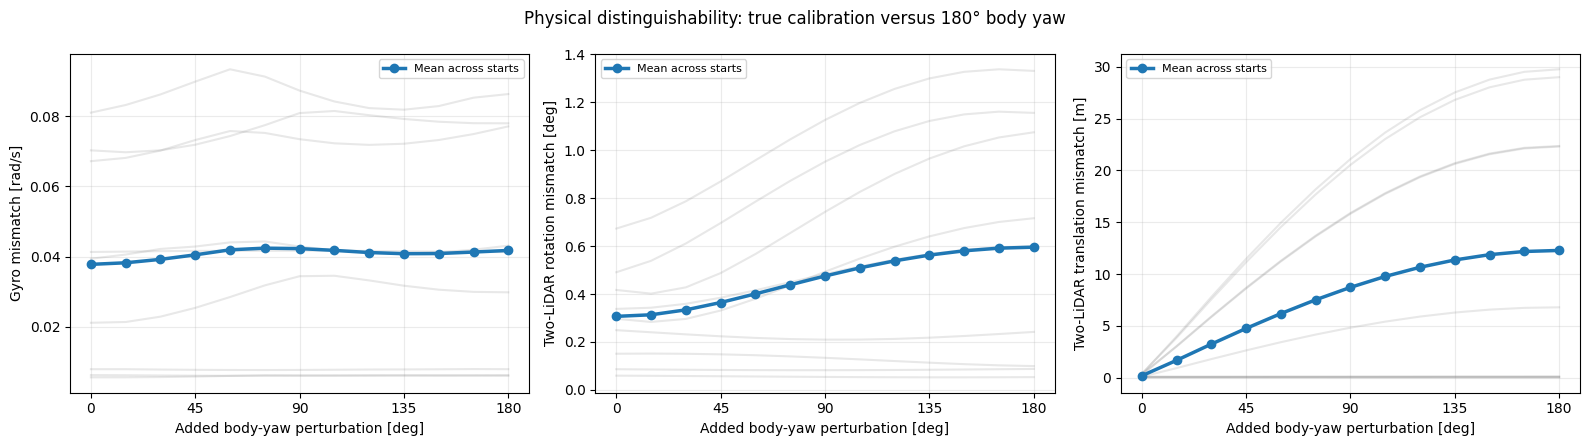

In [10]:

# Appendix B: Does five-second sensor data distinguish 0° and 180° body yaw?

from scipy.spatial.transform import Slerp

PHYSICS_YAW_SWEEP_DEG = np.arange(0.0, 180.1, 15.0)
PHYSICS_CLOCK_OFFSETS_S = np.linspace(-0.30, 0.30, 31)
PHYSICS_MAX_LIDAR_GAP_S = 0.75


def physics_trajectory(stream):
    """Compose end-to-start LiDAR increments into a locally anchored trajectory."""
    ts0 = np_array(stream.interval_start_timestamps)
    ts1 = np_array(stream.timestamps)
    edges = np_array(stream.values)

    if len(edges) < 3 or np.max(ts0[1:] - ts1[:-1]) > PHYSICS_MAX_LIDAR_GAP_S:
        raise ValueError("Missing or discontinuous LiDAR odometry")

    ts = np.r_[ts0[0], ts1]
    if np.any(np.diff(ts) <= 0):
        raise ValueError("Non-increasing LiDAR pose timestamps")

    poses = np.repeat(np.eye(4)[None], len(ts), axis=0)
    for i, edge in enumerate(edges):
        poses[i + 1] = poses[i] @ edge

    return ts, poses, Slerp(ts, SciRotation.from_matrix(poses[:, :3, :3]))


def physics_pose_at(trajectory, t):
    """Interpolate the locally anchored LiDAR pose."""
    ts, poses, rotation_interp = trajectory
    pose = np.eye(4)
    pose[:3, :3] = rotation_interp(float(t)).as_matrix()
    pose[:3, 3] = [np.interp(t, ts, poses[:, d, 3]) for d in range(3)]
    return pose


def physics_body_interval(trajectory, a, b, T_B_S):
    """Express a sensor-relative SE(3) increment in body coordinates."""
    delta_S = np.linalg.inv(physics_pose_at(trajectory, a)) @ physics_pose_at(trajectory, b)
    return T_B_S @ delta_S @ np.linalg.inv(T_B_S)


def physics_gyro_rms(window, R_B_L_candidate):
    """Gyro mismatch minimized over time offset and constant gyro bias."""
    left = window.streams["lidar"]
    gyro = window.streams["gyro"]

    starts = np_array(left.interval_start_timestamps)
    ends = np_array(left.timestamps)
    mid = 0.5 * (starts + ends)
    dt = ends - starts

    w_l = SciRotation.from_matrix(np_array(left.values)[:, :3, :3]).as_rotvec() / dt[:, None]
    w_body_l = w_l @ R_B_L_candidate.T

    t_imu = np_array(gyro.timestamps)
    w_imu = np_array(gyro.values) @ R_B_I.T

    scores = []
    for tau in PHYSICS_CLOCK_OFFSETS_S:
        query = mid + tau
        valid = (query >= t_imu[0]) & (query <= t_imu[-1])

        if valid.sum() < max(6, int(0.8 * len(mid))):
            continue

        w_body_i = np.column_stack([
            np.interp(query[valid], t_imu, w_imu[:, d]) for d in range(3)
        ])

        difference = w_body_i - w_body_l[valid]
        difference -= difference.mean(axis=0, keepdims=True)

        scores.append(np.sqrt(np.mean(np.sum(difference ** 2, axis=1))))

    return float(min(scores)) if scores else np.nan


def physics_lidar_rms(window, R_B_L_candidate):
    """Compare time-aligned left/right LiDAR relative motions in body coordinates."""
    left = physics_trajectory(window.streams["lidar"])
    right = physics_trajectory(window.streams["lidar_right"])

    lo = max(left[0][0], right[0][0]) + 0.12
    hi = min(left[0][-1], right[0][-1]) - 0.12

    if hi - lo < 0.85:
        raise ValueError("Insufficient common LiDAR time")

    grid = np.linspace(lo, hi, 13)

    T_B_L_candidate = np.asarray(T_B_L, dtype=float).copy()
    T_B_L_candidate[:3, :3] = R_B_L_candidate

    angular, linear, motion = [], [], []

    for a, b in zip(grid[:-3], grid[3:]):
        DL = physics_body_interval(left, a, b, T_B_L_candidate)
        DR = physics_body_interval(right, a, b, T_B_L_right)

        E = np.linalg.inv(DR) @ DL

        angular.append(SciRotation.from_matrix(E[:3, :3]).magnitude())
        linear.append(np.linalg.norm(E[:3, 3]))
        motion.append(np.linalg.norm(DR[:3, 3]))

    return (
        float(np.rad2deg(np.sqrt(np.mean(np.square(angular))))),
        float(np.sqrt(np.mean(np.square(linear)))),
        float(np.sqrt(np.mean(np.square(motion)))),
    )


physics_rows = []

for start_id, entry in enumerate(rollouts):
    window = dataset[entry["indices"][0]]

    for yaw_deg in PHYSICS_YAW_SWEEP_DEG:
        R_yaw = SciRotation.from_euler("z", yaw_deg, degrees=True).as_matrix()
        R_candidate = R_yaw @ R_B_L_gt

        try:
            lidar_rot_deg, lidar_trans_m, motion_m = physics_lidar_rms(window, R_candidate)
            gyro_rms = physics_gyro_rms(window, R_candidate)
            error = None
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            lidar_rot_deg = lidar_trans_m = motion_m = gyro_rms = np.nan
            error = str(exc)

        physics_rows.append(dict(
            start_id=start_id,
            sequence=entry["sequence"],
            yaw_perturbation_deg=yaw_deg,
            gyro_rms_radps=gyro_rms,
            lidar_rot_rms_deg=lidar_rot_deg,
            lidar_trans_rms_m=lidar_trans_m,
            lidar_motion_rms_m=motion_m,
            error=error,
        ))

physics_df = pd.DataFrame(physics_rows)
physics_df.to_csv(OUTPUT_DIR / "yaw_0_vs_180_physics.csv", index=False)

# Direct comparison of the correct and 180-degree-flipped hypotheses.
paired = physics_df[physics_df.yaw_perturbation_deg.isin([0.0, 180.0])]

print("Valid paired windows:",
      int(paired.groupby("start_id").lidar_trans_rms_m.count().eq(2).sum()),
      "/", len(rollouts))

for key in ("gyro_rms_radps", "lidar_rot_rms_deg", "lidar_trans_rms_m"):
    pivot = paired.pivot(
        index="start_id",
        columns="yaw_perturbation_deg",
        values=key,
    ).dropna()

    if len(pivot):
        better = int((pivot[0.0] < pivot[180.0]).sum())
        margin = np.median(pivot[180.0] - pivot[0.0])
        print(f"{key}: correct hypothesis has smaller residual in "
              f"{better}/{len(pivot)} windows; median margin = {margin:.4g}")

# Display residual landscapes across yaw perturbations.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = [
    ("gyro_rms_radps", "Gyro mismatch [rad/s]"),
    ("lidar_rot_rms_deg", "Two-LiDAR rotation mismatch [deg]"),
    ("lidar_trans_rms_m", "Two-LiDAR translation mismatch [m]"),
]

for ax, (key, ylabel) in zip(axes, metrics):
    for start_id, part in physics_df.groupby("start_id"):
        ax.plot(part.yaw_perturbation_deg, part[key],
                color="gray", alpha=0.18)

    avg = physics_df.groupby("yaw_perturbation_deg", as_index=False)[key].mean()

    ax.plot(avg.yaw_perturbation_deg, avg[key],
            "o-", linewidth=2.5, label="Mean across starts")

    ax.set(
        xlabel="Added body-yaw perturbation [deg]",
        ylabel=ylabel,
    )
    ax.set_xticks([0, 45, 90, 135, 180])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle("Physical distinguishability: true calibration versus 180° body yaw")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "physics_yaw_0_vs_180.png", dpi=160)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)


In [11]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()